# Double k-means (Vichi, 2001) aplicado à base Spambase

```text
DOUBLE K-MEANS (Vichi, 2001) APLICADO À BASE SPAMBASE (UCI)

 O QUE ESTE SCRIPT FAZ (roteiro do trabalho)
 -------------------------------------------
 1. Lê a base Spambase (4601 e-mails x 57 variáveis + rótulo spam/não-spam)
    e padroniza as 57 variáveis (z-score).
 2. Para cada par (K, H), com K in {2,3,4} e H in {1,...,K}, executa o
    double k-means 100 vezes (100 inicializações aleatórias) e guarda a
    melhor execução segundo a FUNÇÃO OBJETIVO.
 3. Para cada um dos 9 pares (K,H) calcula a silhueta média (Sil) da
    partição de OBJETOS, faz o gráfico Sil x (K,H) e escolhe
            (K*, H*) = arg max Sil(K,H).
 4. Calcula o índice de Rand corrigido (ARI) entre a partição de objetos
    com K* clusters e o rótulo a priori (spam / não-spam), e comenta.
 5. Para o melhor resultado com K*, mostra:
       i)  a matriz de protótipos dos blocos G;
       ii) a matriz de confusão (partição do algoritmo x a priori);
       iv) o gráfico da função objetivo x iterações.

 COMO EXECUTAR
 -------------
 Rode a partir da pasta do projeto (a que contém "data/" e este arquivo):
       Rscript double_kmeans_spambase.R

 DECISÃO DE PROJETO IMPORTANTE
 -----------------------------
 O double k-means é implementado AQUI, do zero (seção 2), em vez de apenas
 chamar o pacote `drclust`. Motivo: o item (iv) pede a função objetivo a
 cada iteração, e o pacote (código compilado em C++) devolve só o resultado
 final. Com implementação própria, a matriz G, a matriz de confusão, a
 silhueta, o ARI e a curva de convergência vêm TODOS da MESMA execução —
 não há risco de o gráfico mostrar uma execução diferente da reportada.
 O pacote `drclust` é usado apenas como VALIDAÇÃO CRUZADA (seção 4): se a
 nossa implementação estiver correta, ela deve alcançar uma função objetivo
 igual (ou melhor) que a do pacote.
```

In [1]:
library(cluster)   # cluster::silhouette  -> silhueta de cada objeto
library(ggplot2)   # gráficos
## `drclust` só é usado na validação cruzada; se não estiver instalado o
## restante do script funciona normalmente.
tem_drclust <- requireNamespace("drclust", quietly = TRUE)

if (!file.exists("data/spambase.data"))
  stop("Execute o script a partir da pasta do projeto (onde existe data/spambase.data).")

out_dir <- "output"
dir.create(out_dir, showWarnings = FALSE)

## 1. DADOS

In [2]:
## O arquivo spambase.data não tem cabeçalho: são 4601 linhas, cada uma um
## e-mail, com 57 atributos numéricos e, na 58ª coluna, o rótulo (1 = spam,
## 0 = não-spam). Os 57 atributos são:
##   * 48 frequências (%) de palavras específicas ("free", "money", ...);
##   * 6 frequências (%) de caracteres (";", "(", "[", "!", "$", "#");
##   * 3 estatísticas sobre sequências de letras MAIÚSCULAS (média, maior, total).
spam <- read.csv("data/spambase.data", header = FALSE)

nomes_vars <- c(
  "word_freq_make","word_freq_address","word_freq_all","word_freq_3d","word_freq_our",
  "word_freq_over","word_freq_remove","word_freq_internet","word_freq_order","word_freq_mail",
  "word_freq_receive","word_freq_will","word_freq_people","word_freq_report","word_freq_addresses",
  "word_freq_free","word_freq_business","word_freq_email","word_freq_you","word_freq_credit",
  "word_freq_your","word_freq_font","word_freq_000","word_freq_money","word_freq_hp",
  "word_freq_hpl","word_freq_george","word_freq_650","word_freq_lab","word_freq_labs",
  "word_freq_telnet","word_freq_857","word_freq_data","word_freq_415","word_freq_85",
  "word_freq_technology","word_freq_1999","word_freq_parts","word_freq_pm","word_freq_direct",
  "word_freq_cs","word_freq_meeting","word_freq_original","word_freq_project","word_freq_re",
  "word_freq_edu","word_freq_table","word_freq_conference","char_freq_semicolon","char_freq_paren",
  "char_freq_bracket","char_freq_bang","char_freq_dollar","char_freq_hash",
  "capital_run_length_average","capital_run_length_longest","capital_run_length_total","spam"
)
colnames(spam) <- nomes_vars

## Partição a priori (usada SOMENTE na avaliação externa: ARI e matriz de
## confusão). O algoritmo nunca enxerga esse rótulo — clustering é não
## supervisionado.
y <- spam$spam

## Matriz de dados X (n x J): só os 57 atributos, sem o rótulo.
X <- as.matrix(spam[, -ncol(spam)])

## PADRONIZAÇÃO (z-score): cada variável fica com média 0 e desvio-padrão 1.
## Por que isso é necessário? As variáveis vivem em escalas muito diferentes
## (frequências em 0–100 versus "capital_run_length_total", que chega à casa
## dos milhares). Sem padronizar, as variáveis de maior escala dominariam a
## soma de quadrados (a função objetivo) e as demais seriam praticamente
## ignoradas. Após o z-score, cada variável tem variância 1, e a soma total
## de quadrados da matriz é exatamente n*J.
Xs <- scale(X)
attr(Xs, "scaled:center") <- NULL   # remove atributos auxiliares, deixando só a matriz
attr(Xs, "scaled:scale")  <- NULL

n <- nrow(Xs)   # número de objetos (e-mails)
J <- ncol(Xs)   # número de variáveis
SQ_TOTAL <- sum(Xs^2)   # soma total de quadrados = n*J (usada p/ % de variância explicada)

cat(sprintf("n = %d objetos, J = %d variáveis (%d spam / %d não-spam)\n",
            n, J, sum(y == 1), sum(y == 0)))

n = 4601 objetos, J = 57 variáveis (1813 spam / 2788 não-spam)


## 2. IMPLEMENTAÇÃO DO DOUBLE K-MEANS

In [3]:
##
##  IDEIA GERAL
##  -----------
##  O k-means comum agrupa apenas as LINHAS (objetos). O double k-means agrupa,
##  ao mesmo tempo, as LINHAS (em K clusters de objetos) e as COLUNAS (em H
##  clusters de variáveis). Isso produz uma "matriz de blocos": cada bloco é o
##  cruzamento de um cluster de objetos com um cluster de variáveis, e é
##  resumido por um único número, o seu protótipo (a média do bloco).
##
##  NOTAÇÃO (a mesma do artigo de Vichi)
##  ------------------------------------
##    X  (n x J) : dados padronizados
##    U  (n x K) : partição dos objetos.   U[i,k] = 1 se o objeto i está no cluster k
##    V  (J x H) : partição das variáveis. V[j,h] = 1 se a variável j está no cluster h
##    G  (K x H) : matriz de protótipos dos blocos (o "Ybar" do artigo);
##                 G[k,h] = média de X no bloco (objetos do cluster k) x (variáveis do cluster h)
##
##  MODELO E FUNÇÃO OBJETIVO
##  ------------------------
##  O modelo aproxima X por uma matriz "em blocos constantes":
##                       B = U %*% G %*% t(V)
##  Ou seja, a previsão para X[i,j] é G[k,h], onde k é o cluster do objeto i
##  e h é o cluster da variável j. O algoritmo MINIMIZA o erro quadrático
##                       || X - B ||^2 .
##  Como G é sempre a média dos blocos, vale a decomposição ortogonal
##                  ||X||^2 = ||B||^2 + ||X - B||^2 ,
##  e como ||X||^2 é constante, minimizar o erro equivale a MAXIMIZAR
##                       f = tr(B'B) = ||B||^2 .
##  Esta é a "função objetivo" do enunciado: quanto MAIOR f, melhor o ajuste.
##  f/||X||^2 é a fração da variância total explicada pelos blocos.
##
##  ALGORITMO (mínimos quadrados alternados)
##  ----------------------------------------
##  Fixadas V e G, atualiza-se U; fixados U e G, atualiza-se V; e G é sempre
##  recalculado como média dos blocos. Cada passo NUNCA piora f, e como há um
##  número finito de partições, o processo converge (para um ótimo LOCAL —
##  por isso rodamos 100 inicializações aleatórias e ficamos com a melhor).
##    passo 0: sorteia U e V aleatórios;
##    repita:
##      (a) G <- médias dos blocos;         U <- cada objeto vai ao cluster
##                                               cujo perfil (linha de G V') está mais perto;
##      (b) G <- médias dos blocos;         V <- cada variável vai ao cluster
##                                               cujo perfil (coluna de U G) está mais perto;
##      (c) G <- médias dos blocos;         f <- tr(B'B);
##    até f parar de crescer (ganho <= tol) ou atingir o máximo de iterações.

## ---------------------------------------------------------------------
## 2.1  Partição aleatória inicial
## ---------------------------------------------------------------------
## Sorteia para cada um dos `m` elementos um rótulo entre 1 e `k` e devolve a
## matriz indicadora (m x k). Repetimos o sorteio até que NENHUM cluster
## fique vazio (cluster vazio quebraria a divisão por tamanho ao calcular G).
particao_aleatoria <- function(m, k) {
  repeat {
    rotulo <- sample.int(k, m, replace = TRUE)
    if (length(unique(rotulo)) == k) break   # todos os k clusters aparecem?
  }
  M <- matrix(0, m, k)
  M[cbind(seq_len(m), rotulo)] <- 1          # marca 1 na posição (elemento, seu cluster)
  M
}

## ---------------------------------------------------------------------
## 2.2  Matriz de protótipos dos blocos G
## ---------------------------------------------------------------------
## G[k,h] = média de X no bloco (objetos do cluster k) x (variáveis do cluster h).
## Em notação matricial:
##      G = (U'U)^{-1}  U' X V  (V'V)^{-1}
##  - U' X V   (K x H) : SOMA dos valores de cada bloco;
##  - U'U e V'V são diagonais e contêm o TAMANHO de cada cluster, então
##    dividir por elas transforma soma em média. Como o número de células de
##    um bloco é (tamanho do cluster de objetos) x (tamanho do de variáveis),
##    usamos outer(tam_U, tam_V) para dividir.
calcula_G <- function(X, U, V) {
  soma_blocos <- t(U) %*% X %*% V
  soma_blocos / outer(colSums(U), colSums(V))
}

## ---------------------------------------------------------------------
## 2.3  Função objetivo f = tr(B'B) = ||B||^2
## ---------------------------------------------------------------------
## B = U G V' repete G[k,h] em todas as (n_k * p_h) células do bloco (k,h),
## logo  ||B||^2 = soma_{k,h} n_k * p_h * G[k,h]^2  (n_k = nº de objetos do
## cluster k, p_h = nº de variáveis do cluster h). Isso evita montar a matriz
## B inteira (4601 x 57), o que deixaria o código bem mais lento.
funcao_objetivo <- function(G, U, V) {
  sum(outer(colSums(U), colSums(V)) * G^2)
}

## ---------------------------------------------------------------------
## 2.4  Passo (a): atualizar a partição dos OBJETOS (U)
## ---------------------------------------------------------------------
## O "perfil" do cluster k de objetos, no espaço das J variáveis, é a linha
## k de (G V'): para cada variável j, o valor G[k, h(j)] do seu bloco.
## O objeto i vai para o cluster k que minimiza a distância euclidiana
## quadrática  ||x_i - perfil_k||^2. Expandindo o quadrado:
##     ||x_i||^2  -  2 * x_i . perfil_k  +  ||perfil_k||^2
## - ||x_i||^2 é igual para todo k, então não influencia o arg min;
## - x_i . perfil_k = soma_h G[k,h] * (soma dos x_ij das variáveis do cluster h)
##                  = (X V)[i,] . G[k,]         -> matriz P = X V  (n x H);
## - ||perfil_k||^2 = soma_h p_h * G[k,h]^2      (p_h = nº de variáveis do cluster h).
## Assim toda a atualização vira poucas multiplicações de matrizes pequenas.
atualiza_U <- function(X, U, V, G, xx_linhas) {
  K  <- ncol(U)
  P  <- X %*% V                                   # n x H: soma das variáveis de cada cluster, por objeto
  prod_cruzado <- P %*% t(G)                      # n x K: x_i . perfil_k
  norma_perfil <- as.vector(G^2 %*% colSums(V))   # K   : ||perfil_k||^2
  ## D = distância ao perfil SEM o termo constante ||x_i||^2 (basta p/ decidir o arg min)
  D <- sweep(-2 * prod_cruzado, 2, norma_perfil, "+")

  rotulo <- max.col(-D, ties.method = "first")    # cluster de menor distância para cada objeto

  ## Tratamento de CLUSTER VAZIO: se algum cluster perdeu todos os objetos,
  ## o double k-means ficaria com K-1 clusters. Corrigimos "emprestando" o
  ## objeto pior ajustado (maior distância ao seu próprio perfil) de um
  ## cluster que tenha mais de 1 objeto, e o colocamos no cluster vazio.
  for (k in setdiff(seq_len(K), unique(rotulo))) {
    dist_propria <- D[cbind(seq_along(rotulo), rotulo)] + xx_linhas   # distância verdadeira ao próprio cluster
    doador_ok    <- tabulate(rotulo, K)[rotulo] > 1                    # só quem não esvazia outro cluster
    dist_propria[!doador_ok] <- -Inf
    rotulo[which.max(dist_propria)] <- k
  }

  U_novo <- matrix(0, nrow(U), K)
  U_novo[cbind(seq_len(nrow(U)), rotulo)] <- 1
  U_novo
}

## ---------------------------------------------------------------------
## 2.5  Passo (b): atualizar a partição das VARIÁVEIS (V)
## ---------------------------------------------------------------------
## É exatamente o passo anterior com os papéis de linhas e colunas trocados.
## O perfil do cluster h de variáveis, no espaço dos n objetos, é a coluna h
## de (U G): para cada objeto i, o valor G[k(i), h] do seu bloco.
## A variável j vai para o cluster h que minimiza  ||x_j - perfil_h||^2, com
##     x_j . perfil_h = soma_k G[k,h] * (soma dos x_ij dos objetos do cluster k)
##                    = (U' X)[,j] . G[,h]      -> matriz R = U'X (K x J);
##     ||perfil_h||^2 = soma_k n_k * G[k,h]^2   (n_k = nº de objetos do cluster k).
atualiza_V <- function(X, U, V, G, xx_colunas) {
  H  <- ncol(V)
  R  <- t(U) %*% X                                # K x J: soma dos objetos de cada cluster, por variável
  prod_cruzado <- t(R) %*% G                      # J x H: x_j . perfil_h
  norma_perfil <- as.vector(t(G^2) %*% colSums(U))# H   : ||perfil_h||^2
  D <- sweep(-2 * prod_cruzado, 2, norma_perfil, "+")

  rotulo <- max.col(-D, ties.method = "first")

  ## Mesmo tratamento de cluster vazio do passo anterior, agora para variáveis.
  for (h in setdiff(seq_len(H), unique(rotulo))) {
    dist_propria <- D[cbind(seq_along(rotulo), rotulo)] + xx_colunas
    doador_ok    <- tabulate(rotulo, H)[rotulo] > 1
    dist_propria[!doador_ok] <- -Inf
    rotulo[which.max(dist_propria)] <- h
  }

  V_novo <- matrix(0, nrow(V), H)
  V_novo[cbind(seq_len(nrow(V)), rotulo)] <- 1
  V_novo
}

## ---------------------------------------------------------------------
## 2.6  UMA execução do double k-means (uma inicialização aleatória)
## ---------------------------------------------------------------------
## Devolve as partições e G finais, e o vetor `f_iter` com o valor da função
## objetivo em cada iteração (posição 1 = valor logo após a inicialização
## aleatória, "iteração 0"). É esse vetor que alimenta o gráfico do item (iv).
dkm_uma_execucao <- function(X, K, H, maxiter = 200, tol = 1e-6,
                             xx_linhas = rowSums(X^2), xx_colunas = colSums(X^2)) {
  U <- particao_aleatoria(nrow(X), K)   # partição aleatória dos objetos
  V <- particao_aleatoria(ncol(X), H)   # partição aleatória das variáveis

  G      <- calcula_G(X, U, V)
  f_iter <- funcao_objetivo(G, U, V)    # f após a inicialização (iteração 0)

  for (it in seq_len(maxiter)) {
    ## (a) fixa V e G, atualiza U; depois recalcula G
    U <- atualiza_U(X, U, V, G, xx_linhas)
    G <- calcula_G(X, U, V)
    ## (b) fixa U e G, atualiza V; depois recalcula G
    V <- atualiza_V(X, U, V, G, xx_colunas)
    G <- calcula_G(X, U, V)
    ## (c) função objetivo ao fim da iteração
    f_iter <- c(f_iter, funcao_objetivo(G, U, V))

    ## CRITÉRIO DE PARADA: para quando o ganho de f nesta iteração é <= tol.
    ## (f nunca diminui; quando o ganho é ~0, nenhum objeto/variável mudou de cluster.)
    if (f_iter[it + 1] - f_iter[it] <= tol) break
  }

  list(U = U, V = V, G = G, f = tail(f_iter, 1), f_iter = f_iter)
}

## ---------------------------------------------------------------------
## 2.7  100 execuções para um par (K,H) e escolha da melhor
## ---------------------------------------------------------------------
## Como o algoritmo só garante ótimo local, repetimos `n_execucoes` vezes com
## partições iniciais diferentes e ficamos com a de MAIOR função objetivo f
## (= menor erro de aproximação). Também devolvemos o f de TODAS as execuções:
## isso permite ver se a melhor solução é encontrada com frequência (ótimo
## "robusto") ou é rara (paisagem com muitos ótimos locais).
dkm_melhor_de_n <- function(X, K, H, n_execucoes = 100, maxiter = 200, tol = 1e-6) {
  xx_linhas  <- rowSums(X^2)    # pré-computados uma vez e reaproveitados nas 100 execuções
  xx_colunas <- colSums(X^2)

  melhor <- NULL
  f_todas <- numeric(n_execucoes)
  for (r in seq_len(n_execucoes)) {
    res <- dkm_uma_execucao(X, K, H, maxiter, tol, xx_linhas, xx_colunas)
    f_todas[r] <- res$f
    if (is.null(melhor) || res$f > melhor$f) melhor <- res   # guarda a de maior f
  }
  melhor$f_todas <- f_todas
  melhor
}

## 3. FUNÇÕES AUXILIARES DE AVALIAÇÃO

In [4]:
## Converte a matriz indicadora U (n x K) em vetor de rótulos 1..K.
rotulos_de <- function(U) max.col(U, ties.method = "first")

## ÍNDICE DE RAND CORRIGIDO (Hubert & Arabie, 1985), a partir da tabela de
## contingência N (linhas = clusters do algoritmo, colunas = classes a priori).
##   Rand simples = fração de PARES de objetos em que as duas partições
##   concordam (ambos juntos ou ambos separados). Problema: mesmo partições
##   aleatórias têm Rand alto. O ARI desconta o valor esperado ao acaso:
##        ARI = (Índice - Esperado) / (Máximo - Esperado)
##   Interpretação: 1 = partições idênticas; ~0 = concordância igual à de
##   partições aleatórias; NEGATIVO = concordância pior que a do acaso.
ari_de_tabela <- function(N) {
  N <- as.matrix(N)
  n_total <- sum(N)
  comb2 <- function(x) x * (x - 1) / 2           # "x escolhe 2" = nº de pares
  soma_celulas <- sum(comb2(N))                  # pares juntos nas DUAS partições
  soma_linhas  <- sum(comb2(rowSums(N)))         # pares juntos na partição do algoritmo
  soma_colunas <- sum(comb2(colSums(N)))         # pares juntos na partição a priori
  esperado <- soma_linhas * soma_colunas / comb2(n_total)   # valor esperado ao acaso
  maximo   <- (soma_linhas + soma_colunas) / 2
  (soma_celulas - esperado) / (maximo - esperado)
}

## 4. GRADE (K,H): 100 EXECUÇÕES POR PAR, MELHOR RESULTADO E SILHUETA

In [5]:
## Grade de pares: K in {2,3,4} e, para cada K, H in {1,...,K}  -> 2+3+4 = 9 pares.
## (H nunca passa de K, como pede o enunciado.)
grade <- do.call(rbind, lapply(2:4, function(K) data.frame(K = K, H = 1:K)))

N_EXEC <- 100   # nº de execuções (inicializações aleatórias) por par (K,H)

## A SILHUETA de um objeto i compara a coesão do seu cluster com a separação
## do cluster vizinho mais próximo:
##     s(i) = (b(i) - a(i)) / max(a(i), b(i))
##   a(i) = distância média de i aos demais objetos do MESMO cluster;
##   b(i) = menor distância média de i aos objetos de OUTRO cluster.
## s(i) perto de +1 => bem agrupado; perto de 0 => na fronteira; negativo =>
## provavelmente no cluster errado. A silhueta média (Sil) resume a partição.
## Ela precisa da matriz de distâncias entre os 4601 objetos; calculamos UMA
## vez (no espaço padronizado completo, com as 57 variáveis) e reaproveitamos
## nos 9 pares. Assim, Sil mede a qualidade da PARTIÇÃO DE OBJETOS em si.
D <- dist(Xs)

set.seed(2026)   # semente fixa => resultados reproduzíveis
resultados <- vector("list", nrow(grade))
todas_f    <- list()   # f de cada uma das 100 execuções, por par (para inspeção)

for (i in seq_len(nrow(grade))) {
  K <- grade$K[i]; H <- grade$H[i]

  ## (a) 100 execuções; `res` já é a melhor segundo a função objetivo
  res <- dkm_melhor_de_n(Xs, K, H, n_execucoes = N_EXEC)

  ## (b) silhueta média da partição de objetos da melhor execução
  cl  <- rotulos_de(res$U)
  sil <- cluster::silhouette(cl, D)
  sil_medio <- mean(sil[, "sil_width"])

  ## (c) VALIDAÇÃO CRUZADA com o pacote drclust::doublekm (opcional).
  ## `prep = 0` porque já padronizamos; o pacote também faz 100 reinícios.
  ## O que esperar: f praticamente IGUAL nos dois quando a melhor solução é
  ## achada com frequência (ex.: H=1, ou (2,2)). Quando a solução ótima é rara
  ## (ex.: (4,4), achada em 1 das 100 execuções), cada método, com sorteios
  ## diferentes, pode terminar num ótimo local ligeiramente distinto — então
  ## uma diferença pequena para cima ou para baixo é normal e NÃO indica erro:
  ## só mostra que 100 reinícios não garantem o ótimo global nesses pares.
  f_pacote <- NA_real_
  if (tem_drclust) {
    out_pkg <- drclust::doublekm(Xs, K = K, Q = H, Rndstart = N_EXEC, maxiter = 200,
                                 tol = 1e-6, prep = 0, verbose = 0, print = 0)
    f_pacote <- out_pkg$betweenss   # "betweenss" do pacote = tr(B'B) = nossa f
  }

  resultados[[i]] <- list(K = K, H = H, res = res, cl = cl, sil_medio = sil_medio,
                          f_pacote = f_pacote)
  todas_f[[i]] <- data.frame(K = K, H = H, execucao = seq_len(N_EXEC), f = res$f_todas)

  cat(sprintf("K=%d H=%d | f=%.2f (%.2f%% var.) | achada em %3d/%d execuções | Sil=%.4f | it=%d | f_drclust=%.2f\n",
              K, H, res$f, 100 * res$f / SQ_TOTAL,
              sum(res$f_todas > res$f - 1e-6 * abs(res$f)), N_EXEC,
              sil_medio, length(res$f_iter) - 1, f_pacote))
}

## Tabela-resumo: um par (K,H) por linha.
resumo <- do.call(rbind, lapply(resultados, function(r) data.frame(
  K = r$K, H = r$H,
  f = r$res$f,                                  # função objetivo da melhor execução
  pct_var = 100 * r$res$f / SQ_TOTAL,           # % da variância total explicada pelos blocos
  execucoes_no_melhor = sum(r$res$f_todas > r$res$f - 1e-6 * abs(r$res$f)),  # quantas das 100 chegaram lá
  f_drclust = r$f_pacote,                       # validação cruzada
  Sil = r$sil_medio)))
cat("\n== Resumo por par (K,H) ==\n")
print(resumo, row.names = FALSE)
write.csv(resumo, file.path(out_dir, "resultados_KH.csv"), row.names = FALSE)
write.csv(do.call(rbind, todas_f), file.path(out_dir, "f_das_100_execucoes.csv"), row.names = FALSE)

K=2 H=1 | f=5742.00 (2.19% var.) | achada em 100/100 execuções | Sil=0.2961 | it=11 | f_drclust=5742.00
K=2 H=2 | f=17766.44 (6.78% var.) | achada em   5/100 execuções | Sil=0.6596 | it=29 | f_drclust=17766.44
K=3 H=1 | f=7841.28 (2.99% var.) | achada em 100/100 execuções | Sil=0.2515 | it=40 | f_drclust=7841.28
K=3 H=2 | f=22878.37 (8.73% var.) | achada em   5/100 execuções | Sil=0.2454 | it=68 | f_drclust=22830.25
K=3 H=3 | f=27817.17 (10.61% var.) | achada em   8/100 execuções | Sil=0.1419 | it=25 | f_drclust=27817.15
K=4 H=1 | f=8976.37 (3.42% var.) | achada em 100/100 execuções | Sil=0.0484 | it=38 | f_drclust=8976.37
K=4 H=2 | f=28899.42 (11.02% var.) | achada em   1/100 execuções | Sil=0.2444 | it=39 | f_drclust=28892.02
K=4 H=3 | f=33733.22 (12.87% var.) | achada em  22/100 execuções | Sil=0.1620 | it=26 | f_drclust=33733.22
K=4 H=4 | f=35069.25 (13.38% var.) | achada em   1/100 execuções | Sil=0.1642 | it=24 | f_drclust=35163.28



== Resumo por par (K,H) ==


 K H         f   pct_var execucoes_no_melhor f_drclust        Sil
 2 1  5742.003  2.189933                 100  5742.003 0.29609380
 2 2 17766.439  6.775911                   5 17766.439 0.65963094
 3 1  7841.282  2.990573                 100  7841.282 0.25146824
 3 2 22878.369  8.725541                   5 22830.251 0.24537948
 3 3 27817.170 10.609142                   8 27817.153 0.14187925
 4 1  8976.369  3.423482                 100  8976.369 0.04842578
 4 2 28899.422 11.021900                   1 28892.017 0.24438815
 4 3 33733.223 12.865455                  22 33733.223 0.16196117
 4 4 35069.253 13.375001                   1 35163.278 0.16416578


## 5. GRÁFICO Sil x (K,H) E ESCOLHA DE K*


>> (K*, H*) = (2, 2)  com Sil = 0.6596 <<


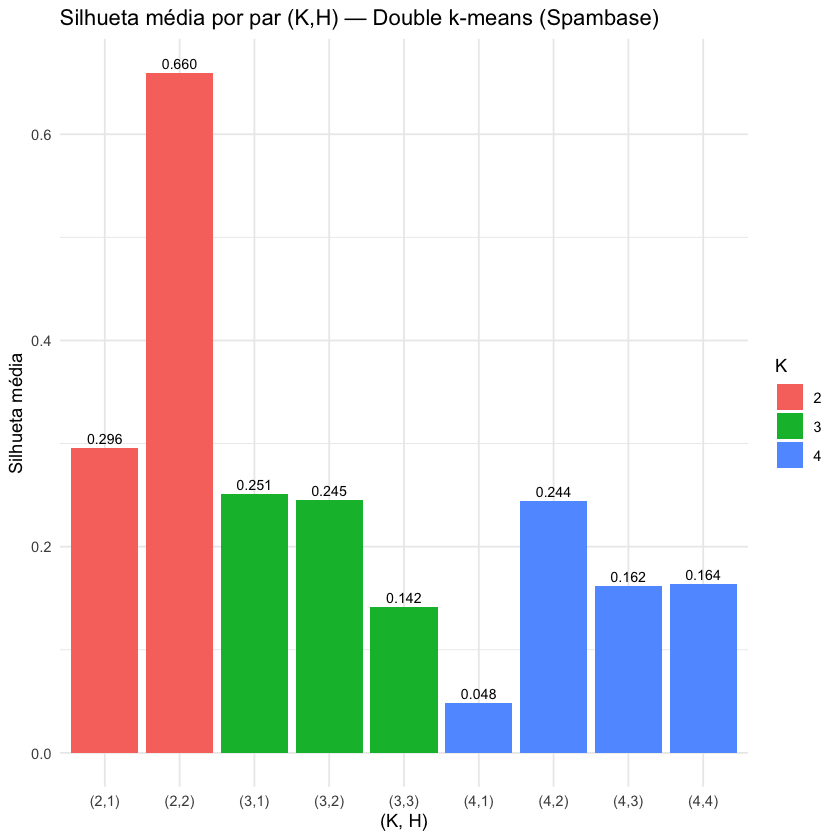

In [6]:
## Rótulo "(K,H)" para o eixo x; `levels` mantém a ordem (2,1),(2,2),(3,1),...
resumo$par <- factor(sprintf("(%d,%d)", resumo$K, resumo$H),
                     levels = sprintf("(%d,%d)", resumo$K, resumo$H))

## Barras coloridas por K facilitam ver que H varia DENTRO de cada K.
p_sil <- ggplot(resumo, aes(x = par, y = Sil, fill = factor(K))) +
  geom_col() +
  geom_text(aes(label = sprintf("%.3f", Sil)), vjust = -0.4, size = 3) +
  labs(x = "(K, H)", y = "Silhueta média", fill = "K",
       title = "Silhueta média por par (K,H) — Double k-means (Spambase)") +
  theme_minimal()
ggsave(file.path(out_dir, "sil_vs_KH.png"), p_sil, width = 7.5, height = 4.5, dpi = 150)
print(p_sil)   # mostra o gráfico também no notebook

## ESCOLHA: (K*, H*) = arg max Sil. O enunciado pede K*, mas como a silhueta
## é calculada por par, o máximo já indica também o H* correspondente.
idx_star <- which.max(resumo$Sil)
Kstar <- resumo$K[idx_star]
Hstar <- resumo$H[idx_star]
cat(sprintf("\n>> (K*, H*) = (%d, %d)  com Sil = %.4f <<\n", Kstar, Hstar, resumo$Sil[idx_star]))

## Recupera a melhor execução do par escolhido. TODOS os itens abaixo (ARI, G,
## confusão e curva de convergência) usam esta MESMA execução `melhor`.
melhor <- resultados[[idx_star]]$res
cl_star <- resultados[[idx_star]]$cl

## 6. ÍNDICE DE RAND CORRIGIDO (ARI) PARA K*

In [7]:
## Tabela de contingência: linhas = clusters do double k-means, colunas =
## rótulo a priori (0 = não-spam, 1 = spam). Cada célula conta os e-mails
## que caem naquele par (cluster, classe).
tabela <- table(cluster = cl_star, classe = y)
ari <- ari_de_tabela(tabela)
cat(sprintf("\nARI (double k-means com K*=%d  vs  rótulo a priori spam/não-spam) = %.4f\n", Kstar, ari))

## Conferência: o nosso ARI deve coincidir com o do pacote (drclust::mrand).
if (tem_drclust) {
  cat(sprintf("   conferência com drclust::mrand: %.4f\n",
              drclust::mrand(matrix(as.numeric(tabela), nrow = nrow(tabela)))))
}
writeLines(sprintf("K*=%d H*=%d ARI=%.6f", Kstar, Hstar, ari), file.path(out_dir, "ari.txt"))

## COMO INTERPRETAR (comentário pedido no enunciado)
## -------------------------------------------------
## O ARI mede o quanto a partição encontrada COINCIDE com a divisão
## spam / não-spam. Se ficar próximo de 0, o algoritmo agrupou os e-mails por
## um critério que NÃO é o de ser spam. Isso não significa que o algoritmo
## "errou": o double k-means (assim como o k-means) minimiza variância
## euclidiana das variáveis padronizadas e não tem acesso ao rótulo. Em
## dados assimétricos como o Spambase (a maioria das frequências é 0 e há
## poucos e-mails com valores extremos), o critério de variância tende a
## isolar OUTLIERS em clusters minúsculos, em vez de separar spam de
## não-spam. A silhueta também pode premiar essas soluções, pois um pequeno
## grupo muito afastado é geometricamente "bem separado". Veja a matriz de
## confusão abaixo para conferir o que cada cluster contém.


ARI (double k-means com K*=2  vs  rótulo a priori spam/não-spam) = -0.0049


   conferência com drclust::mrand: -0.0049


## 7. RESULTADOS DO MELHOR MODELO COM K* (e H* correspondente)


== i) Matriz de protótipos dos blocos G (K* x H*) ==


                     Cluster de variáveis 1 Cluster de variáveis 2
Cluster de objetos 1                  6.860                 -0.144
Cluster de objetos 2                 -0.051                  0.001



Composição dos clusters de variáveis:


  Cluster de variáveis 1 (11 vars): word_freq_hp, word_freq_hpl, word_freq_650, word_freq_lab, word_freq_labs, word_freq_telnet, word_freq_857, word_freq_415
  ...
  Cluster de variáveis 2 (46 vars): word_freq_make, word_freq_address, word_freq_all, word_freq_3d, word_freq_our, word_freq_over, word_freq_remove, word_freq_internet
  ...



== ii) Matriz de confusão (double k-means x a priori) ==


...


== iv) Função objetivo por iteração (melhor execução) ==


 iteracao            f
        0     1.332991
        1  3575.534813
        2  5815.813111
        3  6771.987436
        4  7403.720897
        5  7966.083290
        6  8310.216103
        7  8580.926357
        8  9040.209392
        9  9366.193391
       10 10316.604984
       11 11892.167520
       12 12274.728211
       13 12548.973614
       14 12613.147703
       15 13603.199554
       16 14511.699701
       17 14624.138198
       18 14707.938542
       19 14886.842641
       20 15378.934396
       21 15848.326170
       22 16320.914058
       23 16738.805801
       24 16996.454708
       25 17179.127940
       26 17652.252836
       27 17743.003817
       28 17766.439381
       29 17766.439381



Arquivos gerados em /Users/ernesto/Desktop/IN1102-AM/double-kmeans-spambase/output :


[1] "ari.txt"                   "clusters_de_variaveis.csv"
[3] "f_das_100_execucoes.csv"   "G_prototipos.csv"         
[5] "matriz_confusao.csv"       "objfun_vs_iter.png"       
[7] "resultados_KH.csv"         "sil_vs_KH.png"            



FIM.


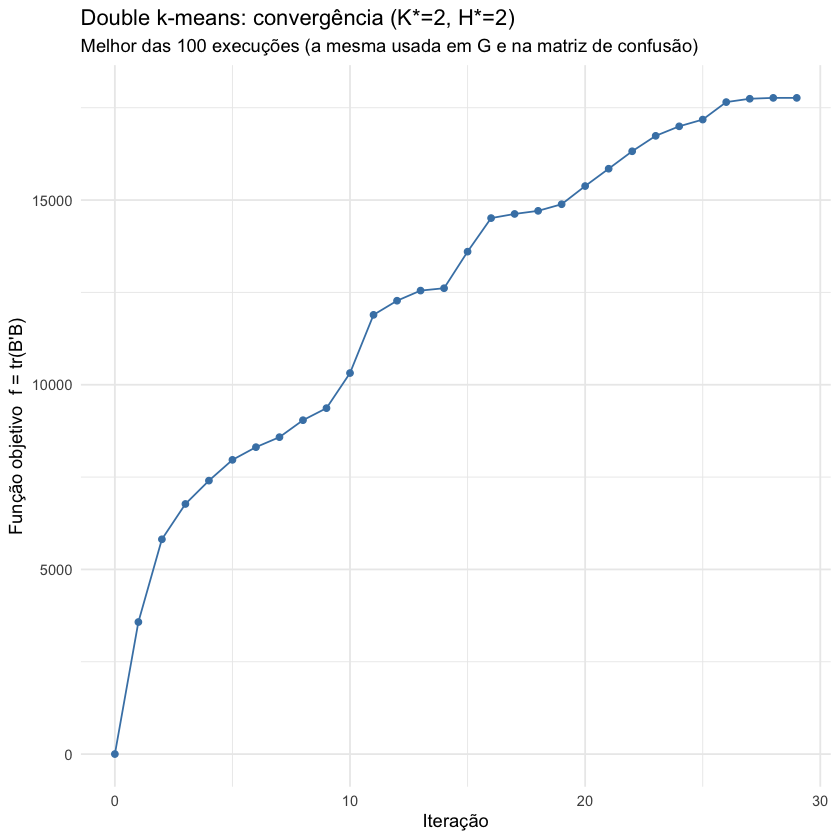

In [8]:
## ---- i) Matriz de protótipos dos blocos G (K* x H*) -----------------
## Cada célula é o valor médio (em desvios-padrão, pois os dados estão em
## z-score) das variáveis do cluster de variáveis h entre os objetos do
## cluster de objetos k. Valores positivos altos = o cluster de objetos tem
## muito mais dessas variáveis que a média geral; negativos = muito menos.
G <- melhor$G
rownames(G) <- paste0("Cluster de objetos ", seq_len(Kstar))
colnames(G) <- paste0("Cluster de variáveis ", seq_len(Hstar))
cat("\n== i) Matriz de protótipos dos blocos G (K* x H*) ==\n")
print(round(G, 3))
write.csv(round(G, 4), file.path(out_dir, "G_prototipos.csv"))

## Quais variáveis ficaram em cada cluster de variáveis (ajuda a interpretar G).
cl_vars <- max.col(melhor$V, ties.method = "first")
cat("\nComposição dos clusters de variáveis:\n")
for (h in seq_len(Hstar)) {
  cat(sprintf("  Cluster de variáveis %d (%d vars): %s\n", h, sum(cl_vars == h),
              paste(head(nomes_vars[-length(nomes_vars)][cl_vars == h], 8), collapse = ", ")),
      if (sum(cl_vars == h) > 8) "  ...\n" else "\n", sep = "")
}
write.csv(data.frame(variavel = nomes_vars[-length(nomes_vars)], cluster_var = cl_vars),
          file.path(out_dir, "clusters_de_variaveis.csv"), row.names = FALSE)

## ---- ii) Matriz de confusão: partição do algoritmo x partição a priori ---
## Linhas = clusters encontrados; colunas = classe verdadeira. Como a
## numeração dos clusters é arbitrária (não há "cluster 1 = não-spam"), a
## tabela deve ser lida procurando em que classe cada cluster se concentra.
confusao <- tabela
rownames(confusao) <- paste0("Cluster ", seq_len(Kstar))
colnames(confusao) <- c("Não-spam (0)", "Spam (1)")
cat("\n== ii) Matriz de confusão (double k-means x a priori) ==\n")
print(confusao)
cat("\nProporção de spam em cada cluster:\n")
print(round(prop.table(confusao, 1)[, "Spam (1)"], 3))
cat(sprintf("(proporção de spam na base inteira: %.3f)\n", mean(y == 1)))
write.csv(as.data.frame.matrix(confusao), file.path(out_dir, "matriz_confusao.csv"))

## ---- iv) Função objetivo x iterações -----------------------------------
## `melhor$f_iter` foi registrado pela PRÓPRIA execução que gerou G e a
## matriz de confusão acima (iteração 0 = após a inicialização aleatória).
## O esperado é uma curva monotonicamente CRESCENTE que estabiliza: cada
## atualização de U, V ou G nunca piora f, e a queda de ganho por iteração
## mostra a convergência para um ótimo local.
iter_df <- data.frame(iteracao = seq_along(melhor$f_iter) - 1, f = melhor$f_iter)

## Sanidade: f não pode decrescer (tolerância numérica minúscula).
stopifnot(all(diff(iter_df$f) >= -1e-6))

p_obj <- ggplot(iter_df, aes(iteracao, f)) +
  geom_line(color = "steelblue") + geom_point(color = "steelblue") +
  labs(x = "Iteração", y = "Função objetivo  f = tr(B'B)",
       title = sprintf("Double k-means: convergência (K*=%d, H*=%d)", Kstar, Hstar),
       subtitle = "Melhor das 100 execuções (a mesma usada em G e na matriz de confusão)") +
  theme_minimal()
ggsave(file.path(out_dir, "objfun_vs_iter.png"), p_obj, width = 6.5, height = 4, dpi = 150)
print(p_obj)   # mostra o gráfico também no notebook

cat("\n== iv) Função objetivo por iteração (melhor execução) ==\n")
print(iter_df, row.names = FALSE)

cat("\nArquivos gerados em", normalizePath(out_dir), ":\n")
print(list.files(out_dir, pattern = "\\.(png|csv|txt)$"))
cat("\nFIM.\n")